# Course 10: AI Research in 2026
## Session 4: Lost in conversation: multi-turn reliability

**Goal:** run the sharded-conversation evaluation protocol on simulated assistants and measure aptitude, unreliability and the gap between single-turn and multi-turn performance.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. The 2026 work behind this lab
**Laban, Hayashi, Zhou and Neville, "LLMs Get Lost In Multi-Turn Conversation"** (ICLR 2026 Outstanding Paper, arXiv 2505.06120) took single-turn benchmark instructions, split each one into "shards" (pieces of information) and revealed them one per turn in simulated conversations. Over 15 models and six generation tasks, the authors report an average drop of 39% compared with giving the whole instruction at once. They split the drop into **aptitude** (the 90th-percentile score over repeated runs, a best case) and **unreliability** (the gap between the 90th and 10th percentiles), and report that the drop is mostly a rise in unreliability. A 2026 follow-up, **Liu et al., "Intent Mismatch Causes LLMs to Get Lost in Multi-Turn Conversation"** (arXiv 2602.07338, a preprint), argues that the cause is a gap between what the user means and what the model infers.

This lab is a toy illustration, not a reproduction. Our "assistants" are a few lines of rules with random choices, not language models. The sizes of the effects come from the rules and numbers we chose. What the toy does show is how the evaluation protocol and its metrics work, and where randomness enters a conversation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
rng0 = np.random.default_rng(0)

### 2. A sharded task
Each task has a hidden specification with 6 details, and each detail has 4 possible values (think of "language: Python", "output: a table", ...). The full instruction states all 6 details in one message. The sharded version reveals one detail per turn: the main request first, then the other 5 in an order the simulated user chooses at random. The score of a conversation is the percentage of details that are right in the assistant's final answer.

In [2]:
N_DETAILS, N_VALUES, N_TASKS, N_RUNS = 6, 4, 200, 10
truth = rng0.integers(0, N_VALUES, size=(N_TASKS, N_DETAILS))
# the assistant's default guess for a detail it has not been told; right 40% of the time
u_default = rng0.random((N_TASKS, N_DETAILS))
offset = rng0.integers(1, N_VALUES, size=(N_TASKS, N_DETAILS))
def make_default(p_right):
    return np.where(u_default < p_right, truth, (truth + offset) % N_VALUES)
default = make_default(0.4)
hard = rng0.random((N_TASKS, N_DETAILS)) < 0.05          # details this assistant gets wrong when it is deterministic
u_keep = rng0.random((N_TASKS, N_DETAILS))               # how stubborn it is about each detail when deterministic
print("task 0, true details:   ", truth[0])
print("task 0, default guesses:", default[0])

task 0, true details:    [3 2 2 1 1 0]
task 0, default guesses: [3 3 0 3 2 1]


### 3. A simulated assistant
The rules, all chosen by us:
- a detail it has been told is used correctly 95% of the time;
- a detail it has not been told is guessed: its default value with probability 0.55, otherwise a random value;
- when a new detail contradicts its current answer, it keeps its earlier assumption with probability $\min(0.9,\ 0.25 \times \text{age})$, where age is the number of turns the assumption has stood in its answers; the longer it has built on a guess, the harder it is to let go;
- at temperature 0 every choice is deterministic for a given task (the `hard` and `u_keep` tables decide); the only randomness left is the order in which the user reveals the details.

Policies: answer from the first turn (**eager**), wait some turns before the first attempt, or answer eagerly and then get a **recap** turn that repeats every detail at the end.

In [3]:
def solve(t, d, rng, temp):
    wrong = hard[t, d] if temp == 0 else rng.random() > 0.95
    return (truth[t, d] + 1) % N_VALUES if wrong else truth[t, d]

def guess(t, d, rng, temp):
    return default[t, d] if (temp == 0 or rng.random() < 0.55) else rng.integers(0, N_VALUES)

def keeps_assumption(t, d, age, rng, temp, stubborn):
    p = min(0.9, stubborn * age)
    return (u_keep[t, d] < p) if temp == 0 else (rng.random() < p)

def conversation(t, rng, temp=1.0, first_answer_turn=1, recap=False, single_turn=False, stubborn=0.25):
    if single_turn:
        return 100 * np.mean([solve(t, d, rng, temp) == truth[t, d] for d in range(N_DETAILS)])
    order = [0] + list(rng.permutation(np.arange(1, N_DETAILS)))      # main request first, then a random order
    answer, age, told = None, np.zeros(N_DETAILS, int), set()
    for turn, d in enumerate(order, start=1):
        told.add(d)
        if turn < first_answer_turn:
            continue                                                   # the assistant asks for more instead of answering
        if answer is None:                                             # first attempt: solve what it knows, guess the rest
            answer = np.array([solve(t, j, rng, temp) if j in told else guess(t, j, rng, temp) for j in range(N_DETAILS)])
        elif answer[d] != truth[t, d] and not keeps_assumption(t, d, age[d], rng, temp, stubborn):
            answer[d] = solve(t, d, rng, temp)                         # it lets go of its earlier assumption
        age += 1
    if recap:                                                          # the user repeats every detail in one last turn
        for d in range(N_DETAILS):
            if answer[d] != truth[t, d] and not keeps_assumption(t, d, age[d], rng, temp, stubborn):
                answer[d] = solve(t, d, rng, temp)
    return 100 * np.mean(answer == truth[t])

rng = np.random.default_rng(1)
print(f"one single-turn run of task 0: {conversation(0, rng, single_turn=True):.1f}")
print("five eager multi-turn runs of task 0:", ", ".join(f"{conversation(0, rng):.1f}" for _ in range(5)))

one single-turn run of task 0: 83.3
five eager multi-turn runs of task 0: 33.3, 66.7, 83.3, 66.7, 66.7


### 4. The protocol: aptitude and unreliability
Run every task 10 times in each setting. For each task, aptitude is the 90th-percentile score of its 10 runs and unreliability is the 90th minus the 10th percentile. Average both over the 200 tasks, as the paper does over its instructions.

setting                              | mean score | aptitude (P90) | unreliability (P90 - P10)
single-turn (full instruction)       |       94.8 |          100.0 |       15.2
sharded, eager                       |       62.2 |           78.8 |       33.5
sharded, eager + final recap         |       65.5 |           82.4 |       33.6


sharded, first answer at turn 3      |       80.2 |           94.9 |       29.4


sharded, waits until told everything |       95.0 |          100.0 |       13.9

eager vs single-turn: mean drop 34.4%, aptitude drop 21.3%, unreliability 15.2 -> 33.5 (+120%)


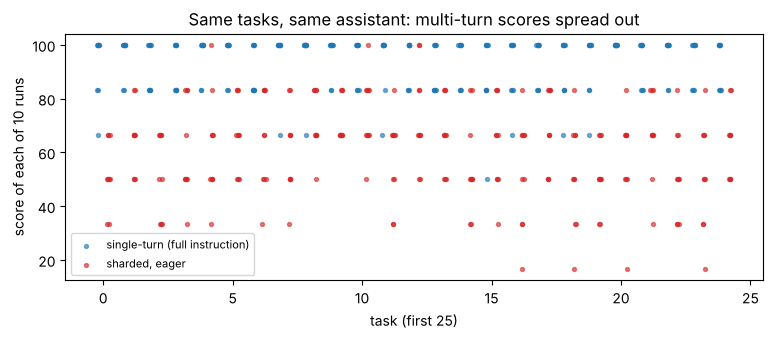

In [4]:
def evaluate(seed=1, **kw):
    rng = np.random.default_rng(seed)
    S = np.array([[conversation(t, rng, **kw) for _ in range(N_RUNS)] for t in range(N_TASKS)])
    p90, p10 = np.percentile(S, 90, axis=1), np.percentile(S, 10, axis=1)
    return {"mean": S.mean(), "aptitude": p90.mean(), "unreliability": (p90 - p10).mean()}, S

settings = {
    "single-turn (full instruction)": dict(single_turn=True),
    "sharded, eager": {},
    "sharded, eager + final recap": dict(recap=True),
    "sharded, first answer at turn 3": dict(first_answer_turn=3),
    "sharded, waits until told everything": dict(first_answer_turn=N_DETAILS),
}
results, scores = {}, {}
print("setting                              | mean score | aptitude (P90) | unreliability (P90 - P10)")
for name, kw in settings.items():
    results[name], scores[name] = evaluate(**kw)
    r = results[name]
    print(f"{name:36s} | {r['mean']:10.1f} | {r['aptitude']:14.1f} | {r['unreliability']:10.1f}")

full, eager = results["single-turn (full instruction)"], results["sharded, eager"]
print(f"\neager vs single-turn: mean drop {100 * (1 - eager['mean'] / full['mean']):.1f}%, "
      f"aptitude drop {100 * (1 - eager['aptitude'] / full['aptitude']):.1f}%, "
      f"unreliability {full['unreliability']:.1f} -> {eager['unreliability']:.1f} "
      f"(+{100 * (eager['unreliability'] / full['unreliability'] - 1):.0f}%)")

fig, ax = plt.subplots(figsize=(9, 3.2))
for k, (name, colour) in enumerate([("single-turn (full instruction)", "C0"), ("sharded, eager", "C3")]):
    for t in range(25):
        ax.scatter(np.full(N_RUNS, t + (0.2 if k else -0.2)) + rng0.normal(0, 0.03, N_RUNS), scores[name][t], s=8, c=colour, alpha=0.6,
                   label=name if t == 0 else None)
ax.set_xlabel("task (first 25)"); ax.set_ylabel("score of each of 10 runs")
ax.set_title("Same tasks, same assistant: multi-turn scores spread out")
ax.legend(fontsize=8, loc="lower left")
plt.show()

### 5. Does a lower temperature fix it?
At temperature 0 our assistant makes the same choice every time for a given task. The user's order of details still varies.

In [5]:
for name, kw in [("single-turn, temperature 0", dict(single_turn=True, temp=0)),
                 ("sharded eager, temperature 0", dict(temp=0)),
                 ("sharded eager + recap, temperature 0", dict(temp=0, recap=True))]:
    r, _ = evaluate(**kw)
    print(f"{name:38s} | mean {r['mean']:5.1f} | aptitude {r['aptitude']:5.1f} | unreliability {r['unreliability']:5.1f}")

single-turn, temperature 0             | mean  95.2 | aptitude  95.2 | unreliability   0.0
sharded eager, temperature 0           | mean  66.8 | aptitude  75.1 | unreliability  16.2
sharded eager + recap, temperature 0   | mean  66.8 | aptitude  75.1 | unreliability  16.2


### 6. Answering too early
How does the score depend on the turn of the first answer attempt?

first answer at turn 1: mean score 62.2
first answer at turn 2: mean score 71.5
first answer at turn 3: mean score 80.2
first answer at turn 4: mean score 88.0
first answer at turn 5: mean score 92.6
first answer at turn 6: mean score 95.0


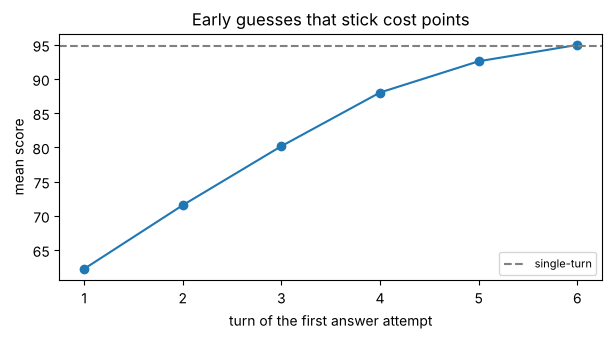

In [6]:
turns = np.arange(1, N_DETAILS + 1)
means = [evaluate(first_answer_turn=k)[0]["mean"] for k in turns]
for k, m in zip(turns, means):
    print(f"first answer at turn {k}: mean score {m:.1f}")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(turns, means, "o-")
ax.axhline(full["mean"], ls="--", c="gray", label="single-turn")
ax.set_xlabel("turn of the first answer attempt"); ax.set_ylabel("mean score")
ax.set_title("Early guesses that stick cost points")
ax.legend(fontsize=8)
plt.show()

### 7. How much of this is our choice?
The split between aptitude and unreliability depends on the toy's settings: how often a default guess is right and how stubborn the assistant is. Change them and watch the numbers move.

In [7]:
f, _ = evaluate(single_turn=True)                       # single-turn does not depend on guesses or stubbornness
print("guess right | stubbornness | mean drop | aptitude drop | unreliability change")
for right in [0.4, 0.6]:
    default = make_default(right)
    for stub in [0.15, 0.25]:
        e, _ = evaluate(stubborn=stub)
        print(f"{right:11.1f} | {stub:12.2f} | {100 * (1 - e['mean'] / f['mean']):8.1f}% | {100 * (1 - e['aptitude'] / f['aptitude']):12.1f}% | "
              f"+{100 * (e['unreliability'] / f['unreliability'] - 1):.0f}%")
default = make_default(0.4)                             # back to the setting used above

guess right | stubbornness | mean drop | aptitude drop | unreliability change
        0.4 |         0.15 |     22.8% |         11.0% | +115%


        0.4 |         0.25 |     34.4% |         21.3% | +120%
        0.6 |         0.15 |     18.4% |          6.7% | +109%


        0.6 |         0.25 |     28.6% |         16.9% | +113%


### 8. The same protocol with a real model (NOT RUN here)

In [ ]:
# NOT RUN: needs `pip install transformers accelerate` and a model download (a GPU makes it much faster)
import re
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

name = "HuggingFaceTB/SmolLM2-360M-Instruct"                 # any small open instruct model will do
tok = AutoTokenizer.from_pretrained(name)
model = AutoModelForCausalLM.from_pretrained(name).to("cuda" if torch.cuda.is_available() else "cpu")

def reply(messages, temperature=1.0, max_new_tokens=200):
    ids = tok.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt").to(model.device)
    kw = dict(do_sample=True, temperature=temperature) if temperature > 0 else dict(do_sample=False)
    out = model.generate(ids, max_new_tokens=max_new_tokens, **kw)
    return tok.decode(out[0, ids.shape[1]:], skip_special_tokens=True)

shards = ["Help me work out how much I spend on tea bags in a year.", "I drink 3 cups a day.",
          "A box of 100 tea bags costs 250 taka.", "I use one tea bag per cup.", "Count a year as 365 days."]
answer = 3 * 365 / 100 * 250                                   # 2737.5 taka

def score(text):                                               # 100 if the last number in the reply is right, else 0
    nums = [float(x.replace(",", "")) for x in re.findall(r"-?\d[\d,]*\.?\d*", text)]
    return 100.0 * (len(nums) > 0 and abs(nums[-1] - answer) < 1)

def run(sharded, temperature=1.0):
    if not sharded:
        return score(reply([{"role": "user", "content": " ".join(shards)}], temperature))
    messages = []
    for s in shards:
        messages.append({"role": "user", "content": s})
        messages.append({"role": "assistant", "content": reply(messages, temperature)})
    return score(messages[-1]["content"])

for sharded in [False, True]:
    S = np.array([run(sharded) for _ in range(10)])
    print("sharded" if sharded else "full   ", "| mean", S.mean(), "| P90", np.percentile(S, 90), "| P90-P10", np.percentile(S, 90) - np.percentile(S, 10))
# One task proves little: write 20 tasks of your own, and keep the per-task P90 and P90-P10 as in section 4.

### 9. Your turn

In [8]:
# TODO: add a "clarifying" assistant. Before its first answer, it asks one question per turn and the user answers
# with one detail it has not been told yet, so it is told two details per turn. Implement it as a new option in
# conversation(), evaluate it as in section 4, and compare its mean, aptitude and unreliability with "eager".
clarifying = None
print("not done yet" if clarifying is None else clarifying)

not done yet


In [9]:
# TODO: measure unreliability with 5 runs per task instead of 10 (N_RUNS = 5), then with 20.
# Does the estimated unreliability change? Why might a paper choose 10?
print("not done yet")

not done yet


### What to notice
- Single-turn, the assistant scored 94.8 on average, with aptitude 100.0 and unreliability 15.2. With the same tasks sharded, the eager assistant scored 62.2, with aptitude 78.8 and unreliability 33.5: a 34.4% drop in the mean, a 21.3% drop in aptitude and a 120% rise in unreliability. In percentage terms that is the same shape as the paper's finding (a modest loss in the best case, a large rise in run-to-run spread), but here the shape follows from our rules.
- Section 7 shows how much the numbers depend on our two settings: the mean drop ranged from 18.4% to 34.4% and the aptitude drop from 6.7% to 21.3%, while unreliability rose by 109% to 120% in all four settings. The toy demonstrates the metrics; it cannot tell you the size of the effect in real models.
- Waiting until every detail was known brought back single-turn performance (mean 95.0, aptitude 100.0). The later the first answer, the better: 62.2 when answering at turn 1, then 71.5, 80.2, 88.0, 92.6 and 95.0. A final recap helped only a little (65.5), because by then the wrong assumptions were old and the assistant held on to them.
- At temperature 0 the single-turn unreliability vanished (0.0), but the multi-turn unreliability stayed at 16.2 and the mean hardly moved (66.8), because the user's order of details still varied. In the toy the recap could not help at temperature 0 at all: an assumption the assistant refused to drop once, it refused again when it was older. This is a property of our rules, not a measured fact about models.